# Mode grids and waveform assembly with `hblteuk.jax`

Phase 4 of the GPU port: the batched stages are wired into a **grid
pipeline** and the mode content is **summed on device** into fields and
waveforms.

- `solve_circular_grid` — drop-in batched replacement for the CPU
  `TeukolskyPointParticleModeGridGenerator.solve` (radiative modes batched,
  the static $m=0$ column stays on the proven CPU path, $m<0$ by
  conjugation). Returns the same `PointParticleModeGrid` object.
- `solve_mode_table` — general $(\ell, m, n)$ tables for eccentric orbits.
- `summation` — batched $S(\theta)$ evaluation, spheroidal→spherical
  projection, and field/waveform einsums.

Design notes: `dev/GPU_PLAN.md` §2.4, `dev/PHASE4.md`; cross-validation in
`examples/jax_pipeline_validation.ipynb`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax

from hblteuk.geo import MiniGeo
from hblteuk import collocode
from hblteuk.mode import TeukolskyPointParticleModeGridGenerator
from hblteuk.jax import solve_circular_grid, waveform_timeseries

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order
print("devices:", jax.devices())

devices: [CpuDevice(id=0)]


## 1. Solve a circular-orbit mode grid

One optimized CPU generator supplies the frozen subdomain structure (and
solves the handful of static $m = 0$ modes); everything radiative goes
through the batched pipeline.

In [2]:
orbit = MiniGeo(0.9, 10.0, 0.0, 1.0)
lmax = 10

solver = collocode.CollocationODEFixedMultiDomainFixedStepSolver(n=32)
gen = TeukolskyPointParticleModeGridGenerator(
    orbit, solver=solver,
    solver_kwargs={"subdomains": 150, "tol": 1e-13, "spacing": "arcsinh7"})
gen.optimize(-2, lmax)

psi4 = solve_circular_grid(orbit, -2, [2, lmax], gen)   # warm-up: compiles
t0 = time.perf_counter()
psi4 = solve_circular_grid(orbit, -2, [2, lmax], gen)
t_jax = time.perf_counter() - t0
print(f"batched grid: {psi4.mode_num} modes in {t_jax:.1f}s "
      f"(incl. {lmax-1} static modes on the CPU path)")

t0 = time.perf_counter()
psi4_cpu = gen(-2, [2, lmax])
t_cpu = time.perf_counter() - t0
print(f"CPU grid generator: {t_cpu:.1f}s  -> speedup {t_cpu/t_jax:.1f}x "
      f"on {jax.devices()[0].platform.upper()}-JAX")

rel = np.max(np.abs(psi4.amplitudes["Up"] - psi4_cpu.amplitudes["Up"])
             / np.abs(psi4_cpu.amplitudes["Up"]))
print(f"amplitude agreement with CPU grid: {rel:.1e}")

batched grid: 117 modes in 0.9s (incl. 9 static modes on the CPU path)


CPU grid generator: 2.1s  -> speedup 2.4x on CPU-JAX
amplitude agreement with CPU grid: 1.7e-09


Small circular grids are the *worst* case for the batched path on
CPU-JAX — the batch is tiny, the serial static column is a fixed cost, and
the scan is latency-bound. The payoff shows on real workloads: the
eccentric $(\ell, m, n)$ table in `examples/jax_source_demo.ipynb` runs
8778 modes at ~1.9 ms/mode (~80× the CPU loop), and the A100 widens the
gap further (`cluster/benchmark_gpu.py`).

In [3]:
# stage split for the batched grid solve (second, compile-free run)
from hblteuk.jax import solve_mode_table
modes_pos = [(l, m) for l in psi4.larray for m in range(1, l + 1)]
la = np.array([c[0] for c in modes_pos]); ma_ = np.array([c[1] for c in modes_pos])
subs = gen.solver_kwargs["subdomains"]
t0 = time.perf_counter()
sol = solve_mode_table(orbit, -2, la, ma_, np.zeros_like(la),
                       subdomains=(subs["Up"], subs["In"]))
sol.amplitudes.block_until_ready()
t_rad = time.perf_counter() - t0
print(f"radiative batch: B = {len(la)} in {t_rad:.2f}s; "
      f"remainder is the static CPU column + host-side grid wiring")

radiative batch: B = 54 in 0.13s; remainder is the static CPU column + host-side grid wiring


## 2. Waveform at scri

The hyperboloidal scaling makes this trivial: the compactified radial
solutions are **regular at $\sigma = 0$ (future null infinity)**, so the
waveform modes are just $\psi_{\ell m}(0)$ — no extraction radius, no
peeling. Summing $\sum_{\ell m} A_{\ell m}\,\psi_{\ell m}(0)\,
S_{\ell m}(\theta)\,e^{i(m\varphi - \omega_m t)}$ over the grid is one
einsum.

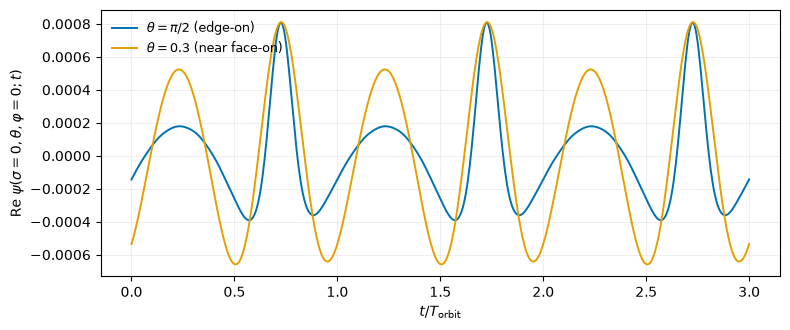

In [4]:
modes = psi4.modes
m_arr = modes[:, 1]
omega = psi4.frequencies
# amplitude-scaled radial solutions at scri (Rslm grids already include A)
r_scri = np.asarray(psi4.Rslm["Up"](np.array([0.0])))[0]      # (nmodes,)
th = np.array([0.3, 0.5 * np.pi])
angular = np.asarray(psi4.Sslm(np.cos(th))).T                 # -> (B, nth)?
angular = angular if angular.shape[0] == len(m_arr) else angular.T

Torb = 2 * np.pi / orbit.frequencies[2]
t_arr = np.linspace(0, 3 * Torb, 600)
wf = np.asarray(waveform_timeseries(np.ones_like(r_scri), r_scri, angular,
                                    m_arr, omega, np.array([0.0]), t_arr))

fig, ax = plt.subplots(figsize=(8, 3.4))
for color, (j, lab) in zip(C, [(1, r"$\theta = \pi/2$ (edge-on)"),
                               (0, r"$\theta = 0.3$ (near face-on)")]):
    ax.plot(t_arr / Torb, wf[j, 0].real, lw=1.4, color=color, label=lab)
ax.set_xlabel(r"$t / T_{\rm orbit}$")
ax.set_ylabel(r"Re $\psi(\sigma{=}0, \theta, \varphi{=}0; t)$")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

## 3. Field snapshot

$|\psi(\sigma, \theta)|$ at $t = \varphi = 0$: Up content outside the
orbit ($\sigma < \sigma_p$), In content inside ($\sigma > \sigma_p$),
assembled with the batched einsum on a $\sigma \times \theta$ grid.

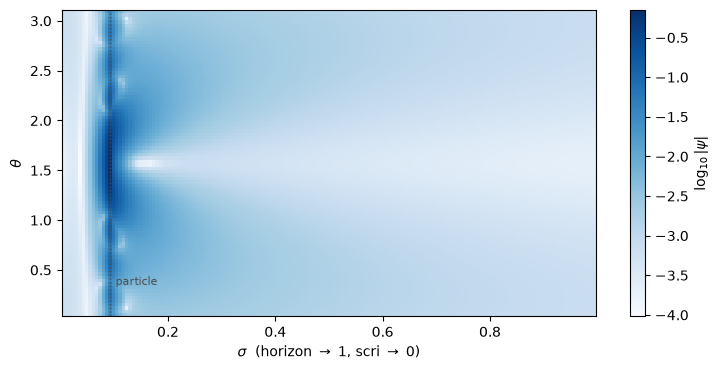

In [5]:
from hblteuk.jax import assemble_field
from hblteuk.teuk import sigma_r
kappa = np.sqrt(1 - orbit.a**2)
sig_p = sigma_r(orbit.radial_roots[0], kappa)

sig = np.linspace(0.005, 0.995, 160)
th_g = np.linspace(0.05, np.pi - 0.05, 90)
rad_up = np.asarray(psi4.Rslm["Up"](sig)).T   # (B, nsig) amplitude-scaled
rad_in = np.asarray(psi4.Rslm["In"](sig)).T
radial = np.where(sig[None, :] <= sig_p, rad_up, rad_in)
ang = np.asarray(psi4.Sslm(np.cos(th_g)))
ang = ang if ang.shape[0] == len(m_arr) else ang.T

field = np.asarray(assemble_field(np.ones(len(m_arr)), radial, ang,
                                  m_arr, omega, np.array([0.0])))[:, :, 0]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.pcolormesh(sig, th_g, np.log10(np.abs(field)).T, cmap="Blues",
                   shading="auto")
ax.axvline(sig_p, color="0.3", ls=":", lw=1)
ax.text(sig_p + 0.01, 0.35, "particle", fontsize=8, color="0.3")
ax.set_xlabel(r"$\sigma$  (horizon $\to$ 1, scri $\to$ 0)")
ax.set_ylabel(r"$\theta$")
fig.colorbar(im, label=r"$\log_{10}|\psi|$")
plt.tight_layout()

## Next

Remaining plan items (`dev/GPU_PLAN.md`): A100 benchmark pass on the
cluster (`cluster/benchmark_gpu.py`), batch chunking for $10^5$-mode
tables, and the downstream hertz/metric reconstruction stage (Phase 6).